In [1]:
%pip install pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv(r"C:\Users\Erin\Downloads\archive (4)\Unemployment in India.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [6]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Number of rows and columns: (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory u

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
count,740,740,740,740.000000,7.400000e+02,740.000000,740
unique,28,14,2,NaN,NaN,NaN,2
top,Andhra Pradesh,31-10-2019,Monthly,NaN,NaN,NaN,Urban
freq,28,55,381,NaN,NaN,NaN,381
mean,NaN,NaN,NaN,11.787946,7.204460e+06,42.630122,NaN
std,NaN,NaN,NaN,10.721298,8.087988e+06,8.111094,NaN
min,NaN,NaN,NaN,0.000000,4.942000e+04,13.330000,NaN
25%,NaN,NaN,NaN,4.657500,1.190404e+06,38.062500,NaN
50%,NaN,NaN,NaN,8.350000,4.744178e+06,41.160000,NaN
75%,NaN,NaN,NaN,15.887500,1.127549e+07,45.505000,NaN



Missing values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Duplicate rows: 27


In [8]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Convert Date to datetime
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

# Convert numerical columns
numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without essential date or unemployment rate
df = df.dropna(
    subset=["Date", "Estimated Unemployment Rate (%)"]
)

# Remove duplicate records
df = df.drop_duplicates()

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

print("Data cleaning completed.")
print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

display(df.head())

Data cleaning completed.
Cleaned dataset shape: (740, 7)

Missing values after cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
2,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
3,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
4,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


In [9]:
unemployment_col = "Estimated Unemployment Rate (%)"

print("Overall unemployment statistics")
print("Mean:", round(df[unemployment_col].mean(), 2), "%")
print("Median:", round(df[unemployment_col].median(), 2), "%")
print("Minimum:", round(df[unemployment_col].min(), 2), "%")
print("Maximum:", round(df[unemployment_col].max(), 2), "%")
print("Standard deviation:", round(df[unemployment_col].std(), 2))

Overall unemployment statistics
Mean: 11.79 %
Median: 8.35 %
Minimum: 0.0 %
Maximum: 76.74 %
Standard deviation: 10.72


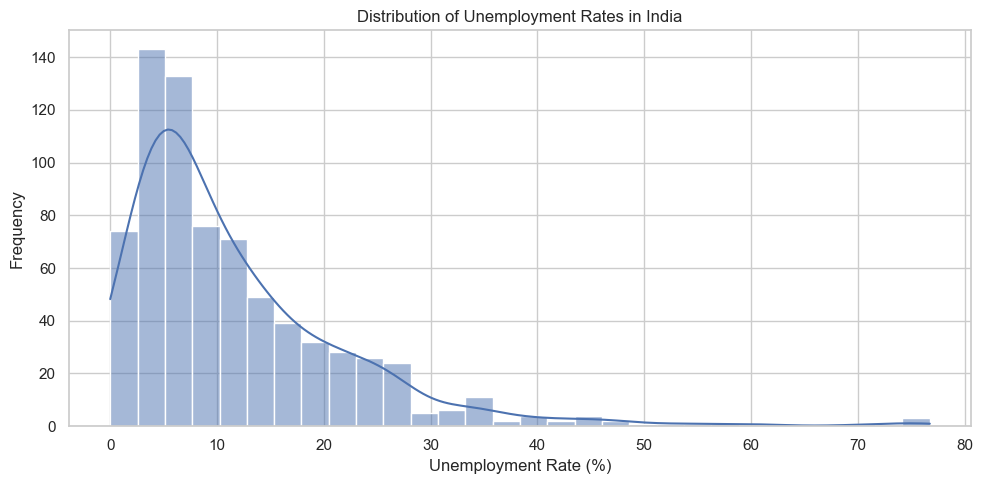

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x=unemployment_col,
    kde=True,
    bins=30
)

plt.title("Distribution of Unemployment Rates in India")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

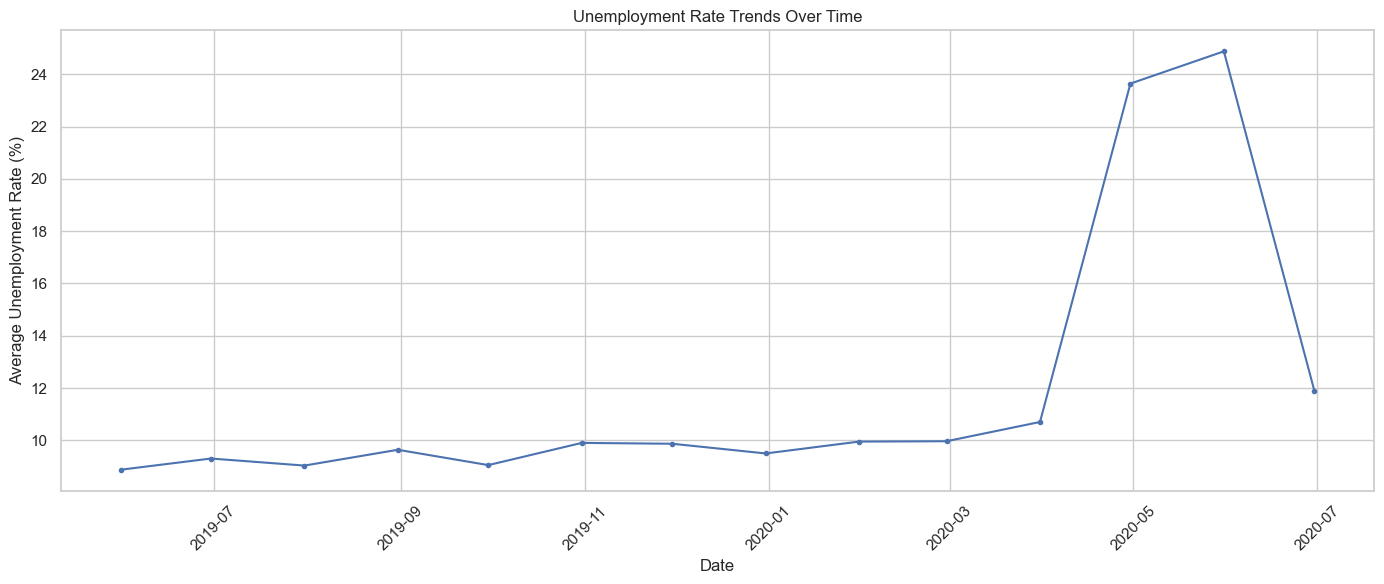

In [11]:
monthly_trend = (
    df.groupby("Date")[unemployment_col]
    .mean()
    .sort_index()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_trend.index,
    monthly_trend.values,
    marker="o",
    markersize=3
)

plt.title("Unemployment Rate Trends Over Time")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
df["COVID Period"] = np.where(
    df["Date"] < pd.Timestamp("2020-03-01"),
    "Pre-COVID",
    "COVID Period"
)

covid_summary = (
    df.groupby("COVID Period")[unemployment_col]
    .agg(["mean", "median", "min", "max", "count"])
    .round(2)
)

display(covid_summary)

,mean,median,min,max,count
COVID Period,,,,,
COVID Period,17.77,14.52,0.0,76.74,204
Pre-COVID,9.51,7.12,0.0,34.69,536


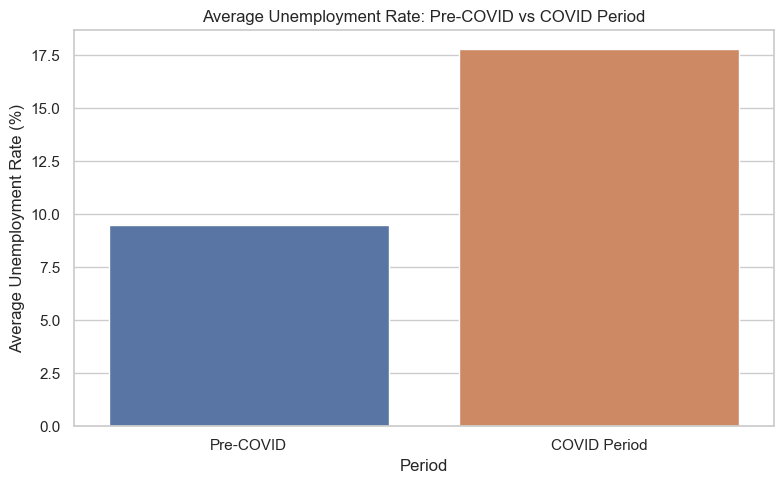

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="COVID Period",
    y=unemployment_col,
    hue="COVID Period",
    legend=False,
    errorbar=None
)

plt.title("Average Unemployment Rate: Pre-COVID vs COVID Period")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

In [14]:
if {"Pre-COVID", "COVID Period"}.issubset(covid_summary.index):
    pre_covid = covid_summary.loc["Pre-COVID", "mean"]
    during_covid = covid_summary.loc["COVID Period", "mean"]

    difference = during_covid - pre_covid

    print(f"Pre-COVID average: {pre_covid:.2f}%")
    print(f"COVID-period average: {during_covid:.2f}%")
    print(f"Difference: {difference:.2f} percentage points")

    if difference > 0:
        print("The average unemployment rate was higher during the defined COVID period.")
    elif difference < 0:
        print("The average unemployment rate was lower during the defined COVID period.")
    else:
        print("The two period averages were equal.")
else:
    print("One of the comparison periods is missing from the dataset.")

Pre-COVID average: 9.51%
COVID-period average: 17.77%
Difference: 8.26 percentage points
The average unemployment rate was higher during the defined COVID period.


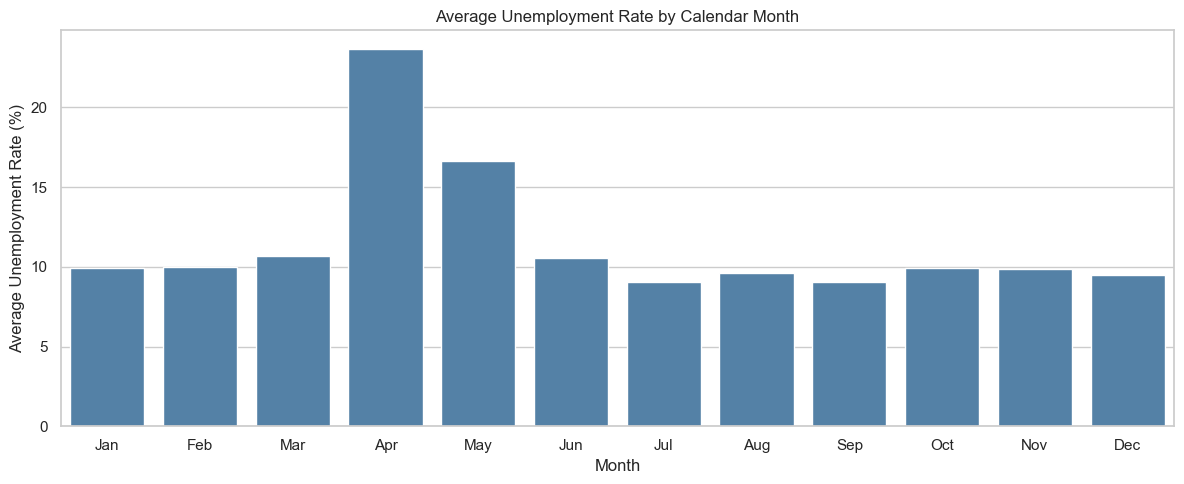

Highest-average month: Apr
Lowest-average month: Jul


In [15]:
df["Month"] = df["Date"].dt.month

monthly_seasonality = (
    df.groupby("Month")[unemployment_col]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 5))

sns.barplot(
    x=month_names,
    y=monthly_seasonality.values,
    color="steelblue"
)

plt.title("Average Unemployment Rate by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

print("Highest-average month:",
      month_names[int(monthly_seasonality.idxmax()) - 1])

print("Lowest-average month:",
      month_names[int(monthly_seasonality.idxmin()) - 1])

Top 10 regions by average unemployment rate:


Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Name: Estimated Unemployment Rate (%), dtype: float64

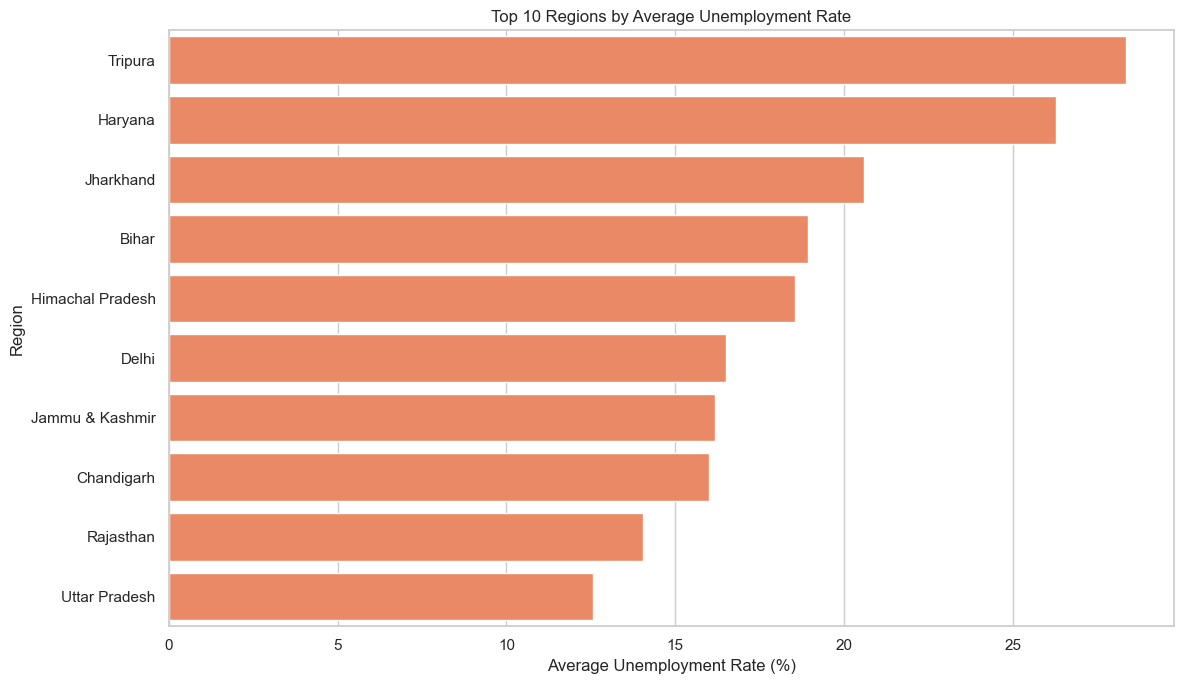

In [16]:
if "Region" in df.columns:
    region_summary = (
        df.groupby("Region")[unemployment_col]
        .mean()
        .sort_values(ascending=False)
    )

    print("Top 10 regions by average unemployment rate:")
    display(region_summary.head(10).round(2))

    plt.figure(figsize=(12, 7))

    sns.barplot(
        x=region_summary.head(10).values,
        y=region_summary.head(10).index,
        color="coral"
    )

    plt.title("Top 10 Regions by Average Unemployment Rate")
    plt.xlabel("Average Unemployment Rate (%)")
    plt.ylabel("Region")
    plt.tight_layout()
    plt.show()

Average unemployment rate by area:


Area
Urban    13.17
Rural    10.32
Name: Estimated Unemployment Rate (%), dtype: float64

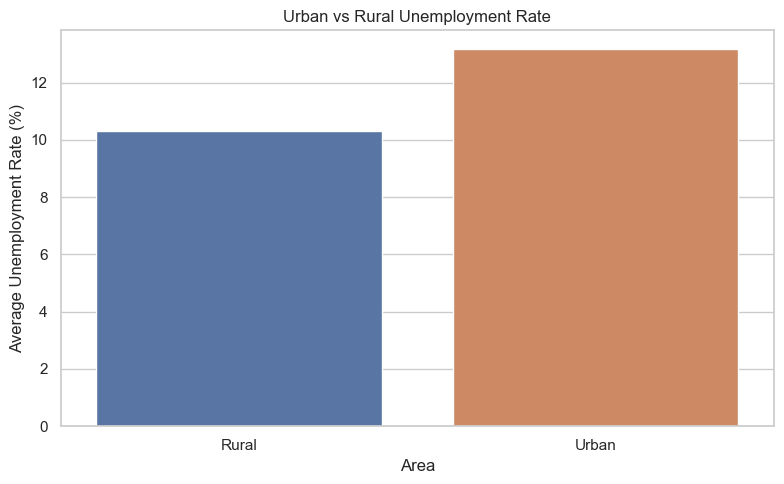

In [17]:
if "Area" in df.columns:
    area_summary = (
        df.groupby("Area")[unemployment_col]
        .mean()
        .sort_values(ascending=False)
    )

    print("Average unemployment rate by area:")
    display(area_summary.round(2))

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=df,
        x="Area",
        y=unemployment_col,
        hue="Area",
        legend=False,
        errorbar=None
    )

    plt.title("Urban vs Rural Unemployment Rate")
    plt.xlabel("Area")
    plt.ylabel("Average Unemployment Rate (%)")
    plt.tight_layout()
    plt.show()

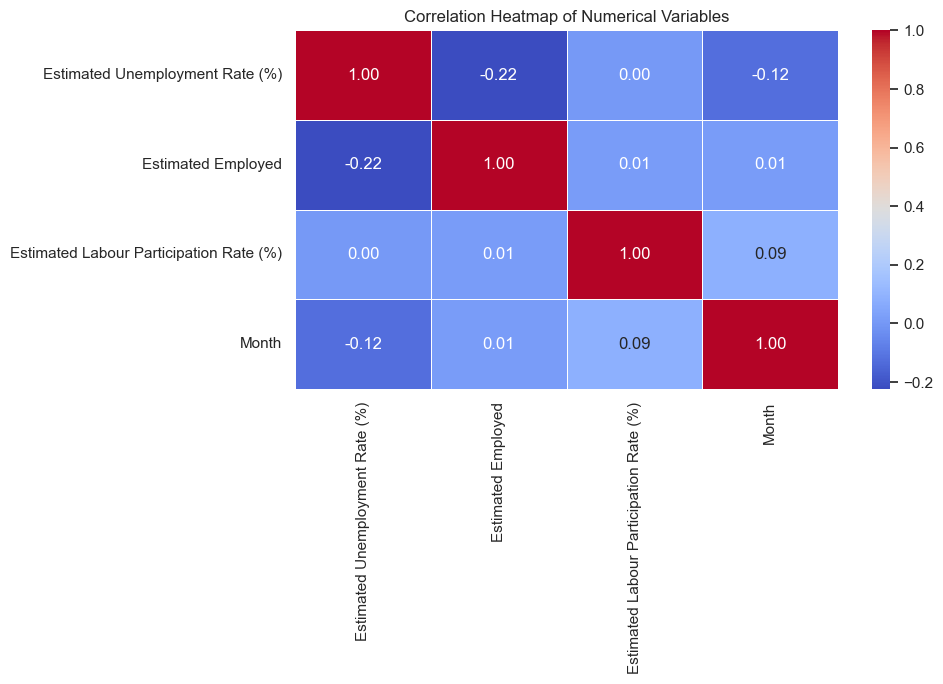

In [18]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

In [19]:
print("=" * 55)
print("KEY FINDINGS")
print("=" * 55)

print(f"1. Overall average unemployment rate: "
      f"{df[unemployment_col].mean():.2f}%")

highest_idx = df[unemployment_col].idxmax()
lowest_idx = df[unemployment_col].idxmin()

print(f"\n2. Highest recorded rate: "
      f"{df.loc[highest_idx, unemployment_col]:.2f}% "
      f"on {df.loc[highest_idx, 'Date'].date()}")

print(f"3. Lowest recorded rate: "
      f"{df.loc[lowest_idx, unemployment_col]:.2f}% "
      f"on {df.loc[lowest_idx, 'Date'].date()}")

if {"Pre-COVID", "COVID Period"}.issubset(covid_summary.index):
    change = (
        covid_summary.loc["COVID Period", "mean"]
        - covid_summary.loc["Pre-COVID", "mean"]
    )
    print(f"\n4. COVID-period average change: {change:+.2f} percentage points")

if monthly_seasonality.notna().any():
    print(f"\n5. Highest-average calendar month: "
          f"{month_names[int(monthly_seasonality.idxmax()) - 1]}")
    print(f"6. Lowest-average calendar month: "
          f"{month_names[int(monthly_seasonality.idxmin()) - 1]}")

if "Region" in df.columns:
    print(f"\n7. Highest-average region: {region_summary.index[0]}")
    print(f"8. Lowest-average region: {region_summary.index[-1]}")

KEY FINDINGS
1. Overall average unemployment rate: 11.79%

2. Highest recorded rate: 76.74% on 2020-04-30
3. Lowest recorded rate: 0.00% on 2019-05-31

4. COVID-period average change: +8.26 percentage points

5. Highest-average calendar month: Apr
6. Lowest-average calendar month: Jul

7. Highest-average region: Tripura
8. Lowest-average region: Meghalaya
